# Gas–Oil Divergence to Alpha — U.S. LNG
Research-grade falsification pilot, 2026-10-19. **Not an investable backtest.**

## Hypotheses
H1: expensive WTI relative to Henry Hub on a rough energy-equivalent basis predicts future gas price increases. H2: the spread improves forecasting beyond momentum controls. H3: any improvement survives regime and lagged-placebo checks.


> **Verification status.** This is a frozen-source price forecasting study, **not a tradable LNG equity or futures backtest**. Measured headline numbers below come from the repository's stored analysis and README. Additional chart and diagnostic cells are not yet archived as executed notebook outputs; CI/run-all verification is required.


## 0A. Economic thesis versus tradable factor
LNG export terminals, feedgas pipelines, liquefaction turbines and shipping can benefit from rising global demand, but **WTI vs Henry Hub** is not a real LNG arbitrage pair: gas must be liquefied, shipped and delivered, and global marginal prices often depend on JKM/TTF. A capacity-growth thesis does not imply higher Henry Hub spot prices, nor does a spot-price forecast imply equity alpha. The experiment below attempts to falsify the narrow price-divergence hypothesis rather than claim broad LNG investment performance.


In [1]:
from run_analysis import load_data,make_panel,evaluate,score,run
import pandas as pd
df=load_data()
print('Source rows:',len(df),'first:',df.date.min(),'last:',df.date.max())
display(df.tail())

Source rows: 357 first: 1997-01-01 00:00:00 last: 2026-09-01 00:00:00


,date,henry_hub_usd_mmbtu,wti_usd_barrel
352,2026-05-01,2.94,102.13
353,2026-06-01,3.15,84.81
354,2026-07-01,2.89,80.46
355,2026-08-01,2.78,83.90
356,2026-09-01,2.95,97.31


## 1A. Source register and measurement quality
The frozen monthly price matrix covers **357 observations (1997-01–2026-09)** from EIA-origin Henry Hub USD/MMBtu and WTI USD/barrel series obtained through archived DataHub GitHub mirrors. It is **not a series of what each forecaster knew on every historical release date**. The data/source register contains URLs, freeze dates, units, roles and these limitations. No synthetic company financial statements or fake stock returns are supplied.


In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
source=pd.read_csv('data/source_register.csv')
display(source)
assert df.date.is_monotonic_increasing and df.date.is_unique
assert (df[['henry_hub_usd_mmbtu','wti_usd_barrel']] > 0).all().all()


,dataset,original_provider,mirror,frequency,units,coverage,mirror_commit_utc,mirror_commit_sha,source_url,quality,release_lag_assumption,historical_vintage_verified,use
0,Henry Hub spot,EIA,datasets/natural-gas,monthly average,USD/MMBtu,1997-01 to 2026-09,2026-10-08T05:29:19Z,46333b1b23502827393563e46e60210604c1fcdb,https://github.com/datasets/natural-gas/blob/4...,A-source B-vintage,one completed month,NO,target and own-price momentum
1,WTI Cushing spot,EIA,datasets/oil-prices,monthly average,USD/barrel,1997-01 to 2026-09,2026-10-08T06:46:11Z,5b9f941b232aa62263ad4798e1eb68dd1932ab3c,https://github.com/datasets/oil-prices/blob/5b...,A-source B-vintage,one completed month,NO,oil momentum and oil-gas spread
2,LNG exports 2026-2027 forecast,EIA,official press mirror,published 2026-04-16,Bcf/day,2026-2027,2026-04-16,NaN,https://ebs.publicnow.com/view/3450355AF1FDD5D...,A,qualitative only,dated forecast,industry thesis
3,LNG exports first half 2026,EIA,official press mirror,published 2026-09-01,Bcf/day,2026 H1,2026-09-01,NaN,https://ebs.publicnow.com/view/6AF62E0FFC43478...,A,qualitative only,dated report,industry thesis
4,Annual Energy Outlook 2026,EIA,official PDF,2026 edition,Bcf/day capacity,to 2050,2026,NaN,https://www.eia.gov/outlooks/aeo/pdf/AEO_Narra...,A,qualitative only,dated outlook,capacity thesis


## 1B. Raw commodity regime inspection
Visualizations are **descriptive** only: they contextualize shocks and regime changes rather than validate forecasts. Since both spot prices are volatile, plotting log scales helps distinguish secular trends from isolated price spikes.


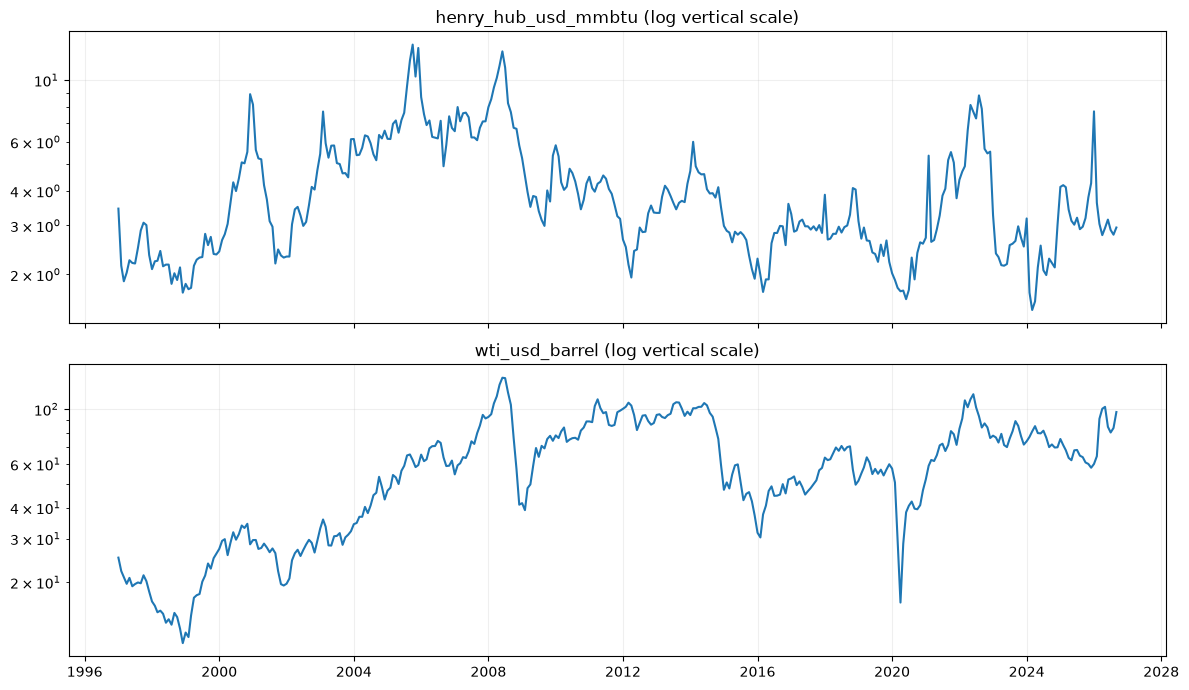

In [3]:
fig,axs=plt.subplots(2,1,figsize=(12,7),sharex=True)
for ax,col in zip(axs,['henry_hub_usd_mmbtu','wti_usd_barrel']):
 ax.plot(df.date,df[col]);ax.set_yscale('log');ax.set_title(col+' (log vertical scale)');ax.grid(alpha=.2)
plt.tight_layout();plt.show()


## 1C. Energy-equivalent normalization is not arbitrage
\[s_t=\log\left(\frac{WTI_{t-1}}{6\cdot HenryHub_{t-1}}\right).\]
Six MMBtu per barrel is an approximate energy-equivalence convention. It **ignores liquefaction, transportation, destination basis, contractual caps, storage and cross-fuel constraints**. The fixed log transform avoids fitting a look-ahead normalization from the full test period, but the economically correct competitor factor may be *JKM netback minus U.S. gas plus shipping*.


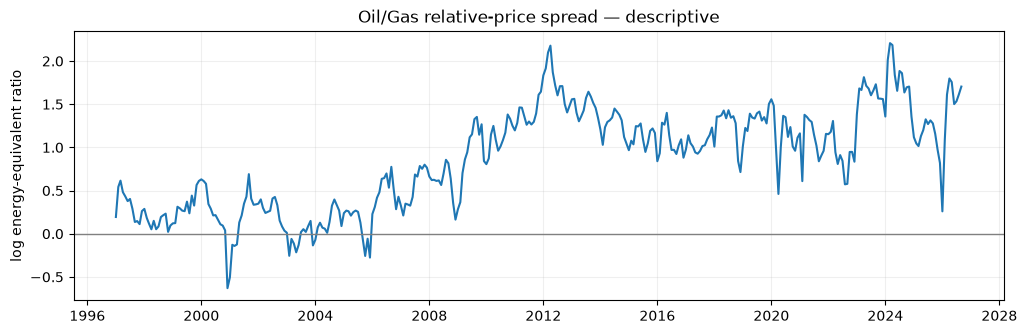

In [4]:
spread=np.log(df['wti_usd_barrel'].to_numpy()/(6*df['henry_hub_usd_mmbtu'].to_numpy()))
fig,ax=plt.subplots(figsize=(12,3.5));ax.plot(df.date,spread);ax.axhline(0,color='gray',lw=1);ax.set_ylabel('log energy-equivalent ratio');ax.set_title('Oil/Gas relative-price spread — descriptive');ax.grid(alpha=.2);plt.show()


## Point-in-time discipline
At forecast month t, all features use t−1 or earlier; y = 100·log[Gas(t+3)/Gas(t−1)]. Train rows u satisfy u+3 ≤ t−1. One-month source lag is an assumption, not verified historical vintage availability.


In [5]:
panel=make_panel(df,3)
display(panel.head())
pred=evaluate(df,3)
display(pd.DataFrame(score(pred)).T)
assert len(pred)==242

,t,date,y,gas_mom3,gas_mom12,wti_mom3,wti_mom12,oil_gas_spread
0,13,1998-02,2.364176,-38.451350,-50.121017,-24.350892,-40.745674,0.287682
1,14,1998-03,-2.727442,-29.993849,3.653374,-22.885572,-32.285927,0.182571
2,15,1998-04,-3.174870,-4.793946,16.989904,-19.252069,-32.707447,0.117783
3,16,1998-05,-27.270562,15.072719,17.985546,-8.549013,-24.950316,0.051465
4,17,1998-06,-5.770832,-4.119576,-5.012439,-7.429958,-33.388193,0.149467


,rmse,mae,hit_rate
n,242,242,242
start,2006-05,2006-05,2006-05
end,2026-06,2026-06,2026-06
mean,30.824804,23.660276,0.392562
control,30.911366,23.311875,0.586777
full,32.706874,25.039791,0.557851
spread_only,32.682024,25.360103,0.471074
gas_only,31.169669,23.774782,0.520661
gas_spread,33.267304,25.36168,0.495868
delta_rmse_control_minus_full,-1.795508,-1.795508,-1.795508


## 2A. Predictors, information cutoff and target
Forecast at calendar month \(t\) uses 3- and 12-month gas and WTI log momentum measured only through \(t-1\), plus the contemporaneously *lagged* relative-price factor. Outcome is \(y_{t,h}=100\log(G_{t+h}/G_{t-1})\), so the primary \(h=3\) target spans **four months from the last observable level**, not a three-month directly fillable forward spot trade. Training origins \(u\) are eligible only when \(u+h\le t-1\). No test-period targets, all-sample scaling or futures P&L are used as features.


,y,gas_mom3,gas_mom12,wti_mom3,wti_mom12,oil_gas_spread
count,341.000,341.000,341.000,341.000,341.000,341.000
mean,0.317,0.038,1.210,1.401,4.335,0.877
std,30.297,26.583,47.561,20.220,36.179,0.575
min,-96.540,-102.497,-135.314,-124.575,-135.031,-0.630
5%,-50.693,-41.900,-85.823,-30.963,-62.838,0.011
25%,-17.548,-16.077,-28.768,-7.689,-15.714,0.335
50%,-0.280,-0.487,4.001,3.430,6.655,0.971
75%,19.327,16.375,31.468,12.881,29.390,1.327
95%,48.862,41.120,75.964,27.353,58.744,1.710
max,95.525,88.379,132.739,90.009,131.622,2.207


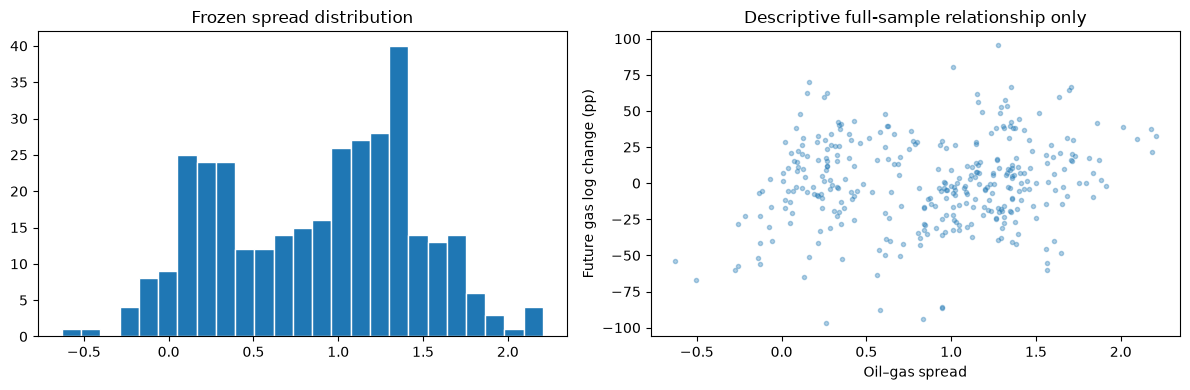

In [6]:
display(panel[['y','gas_mom3','gas_mom12','wti_mom3','wti_mom12','oil_gas_spread']].describe(percentiles=[.05,.25,.5,.75,.95]).round(3))
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].hist(panel.oil_gas_spread,bins=25,edgecolor='white');axs[0].set_title('Frozen spread distribution')
axs[1].scatter(panel.oil_gas_spread,panel.y,s=9,alpha=.35);axs[1].set_xlabel('Oil–gas spread');axs[1].set_ylabel('Future gas log change (pp)');axs[1].set_title('Descriptive full-sample relationship only')
plt.tight_layout();plt.show()


## 2B. Primary model comparison
Both challenger and momentum-control regressions use expanding-window Ridge with **96 matured labels minimum**, \(\alpha=10\), train-only centered/scaled predictors, and identical out-of-sample test origins. Also score historical mean, spread only, gas only, and gas+spread ablations. Report RMSE, MAE and sign accuracy, but **not Sharpe, trading return or annualized alpha**.


In [7]:
results=score(pred)
rows=[]
for model in ['mean','control','full','spread_only','gas_only','gas_spread']:
 rows.append({'model':model,**results[model]})
display(pd.DataFrame(rows).set_index('model').round(4))
assert results['n']==len(pred)


,rmse,mae,hit_rate
model,,,
mean,30.8248,23.6603,0.3926
control,30.9114,23.3119,0.5868
full,32.7069,25.0398,0.5579
spread_only,32.6820,25.3601,0.4711
gas_only,31.1697,23.7748,0.5207
gas_spread,33.2673,25.3617,0.4959


### Observed headline values (frozen snapshot)
Across **242** expanding-window origins, historical mean RMSE = **30.825 pp**, momentum-control RMSE = **30.911 pp**, and momentum + oil/gas spread RMSE = **32.707 pp**. Adding the spread worsens accuracy by **1.796 pp** versus controls; this explicitly *rejects* a claim of incremental predictive value.


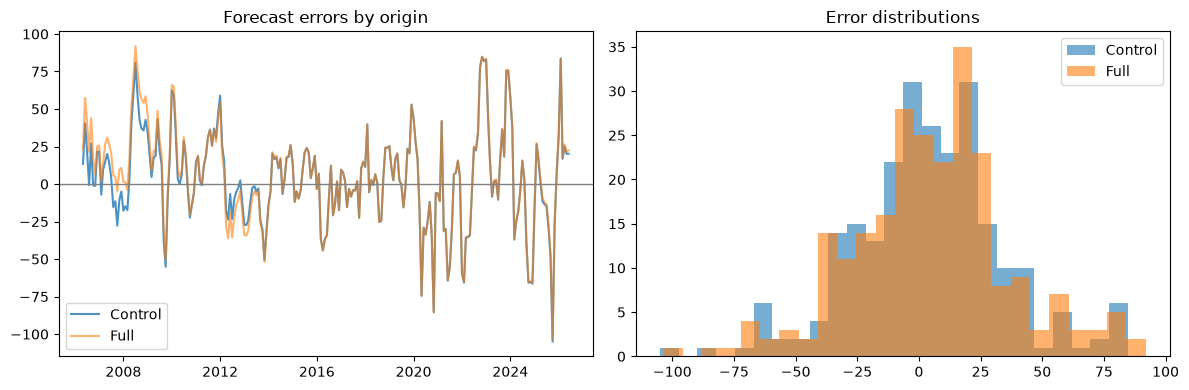

In [8]:
e=pred[['mean','control','full']].sub(pred.y,axis=0)
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(pd.to_datetime(pred.date),e.control,alpha=.8,label='Control')
axs[0].plot(pd.to_datetime(pred.date),e.full,alpha=.6,label='Full');axs[0].axhline(0,color='gray',lw=1);axs[0].legend();axs[0].set_title('Forecast errors by origin')
axs[1].hist(e.control,bins=25,alpha=.6,label='Control');axs[1].hist(e.full,bins=25,alpha=.6,label='Full');axs[1].legend();axs[1].set_title('Error distributions')
plt.tight_layout();plt.show()


## 2C. Conditional model failures
RMSE penalizes large failures; a small number of gas price spikes can dominate performance. Quantify paired squared-error improvements and examine distribution rather than reporting a single aggregate statistic. With overlapping months, these observations are autocorrelated and naive nominal significance is invalid.


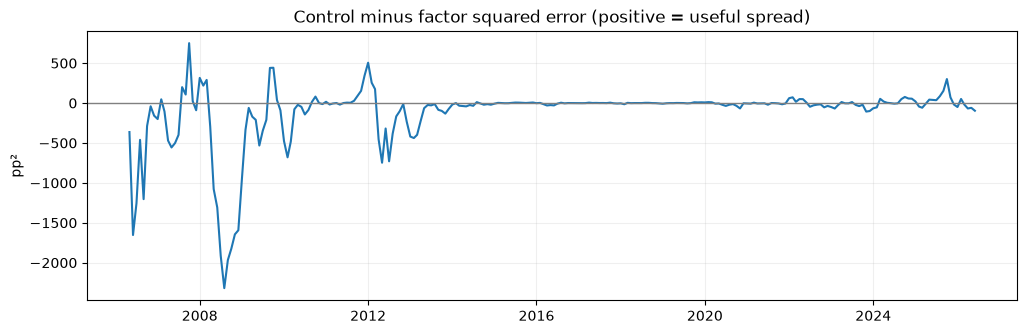

Mean paired loss improvement: -114.22704802003467


In [9]:
loss_gain=(pred.y-pred.control)**2-(pred.y-pred.full)**2
fig,ax=plt.subplots(figsize=(12,3.5));ax.plot(pd.to_datetime(pred.date),loss_gain);ax.axhline(0,color='gray',lw=1);ax.set_title('Control minus factor squared error (positive = useful spread)');ax.set_ylabel('pp²');ax.grid(alpha=.2);plt.show()
print('Mean paired loss improvement:',float(loss_gain.mean()))


## Robustness and negative controls
Expanding Ridge α=10 with train-only scaling and 96 minimum labels; historical-mean baseline, momentum controls, spread-enhanced model, and ablations. Test 1- and 6-month targets, 2016 LNG-era split, 2022 exclusion, and stale-spread 12/24/36-month placebos. Overlapping outcomes imply serial dependence.


In [10]:
res=run(write=False)
for section in ('robustness','stale_spread_placebos'):
 print(section)
 display(pd.DataFrame({k:{'n':v['n'],'control_rmse':v['control']['rmse'],'full_rmse':v['full']['rmse'],'delta':v['delta_rmse_control_minus_full']} for k,v in res[section].items()}).T)
print('Moving-block bootstrap CI:',res['bootstrap_95_ci_delta_rmse'])

robustness


,n,control_rmse,full_rmse,delta
h1,246.0,22.026455,22.665198,-0.638743
h6,236.0,40.438426,44.517408,-4.078982
pre2016,116.0,25.641522,29.907541,-4.266020
since2016,126.0,35.069713,35.087138,-0.017425
since2020,78.0,41.899498,41.906535,-0.007036
excluding_2022,230.0,29.300360,31.287867,-1.987508


stale_spread_placebos


,n,control_rmse,full_rmse,delta
spread_lag_12,230.0,31.466028,32.071080,-0.605052
spread_lag_24,218.0,32.271649,33.151435,-0.879786
spread_lag_36,206.0,31.286583,32.426513,-1.139930


Moving-block bootstrap CI: [-3.4518315855977932, -0.2481673613890422]


## 3A. Horizon sensitivity is a necessary rejection test
At **1 month**, spread model RMSE **22.665 vs control 22.026**; at **6 months**, **44.517 vs 40.438**. A factor that only works at a cherry-picked horizon is especially suspect; here it fails even these alternatives.


In [11]:
alt=[]
for k,v in res['robustness'].items():
 alt.append({'case':k,'n':v['n'],'control':v['control']['rmse'],'full':v['full']['rmse'],'delta':v['delta_rmse_control_minus_full']})
display(pd.DataFrame(alt).set_index('case').round(3))


,n,control,full,delta
case,,,,
h1,246,22.026,22.665,-0.639
h6,236,40.438,44.517,-4.079
pre2016,116,25.642,29.908,-4.266
since2016,126,35.070,35.087,-0.017
since2020,78,41.899,41.907,-0.007
excluding_2022,230,29.300,31.288,-1.988


## 3B. LNG era, 2022 energy shock and model instability
Pre-2016 is not the same industrial regime as high-export LNG years; 2022 introduces extraordinary geopolitical disruption. In the stored analysis, pre-2016 gap performance is weak and post-2016 barely changes RMSE; after removing 2022, results are still negative. These are **descriptive splits** that must be interpreted with the smaller effective sample and risk of retrospective selection.


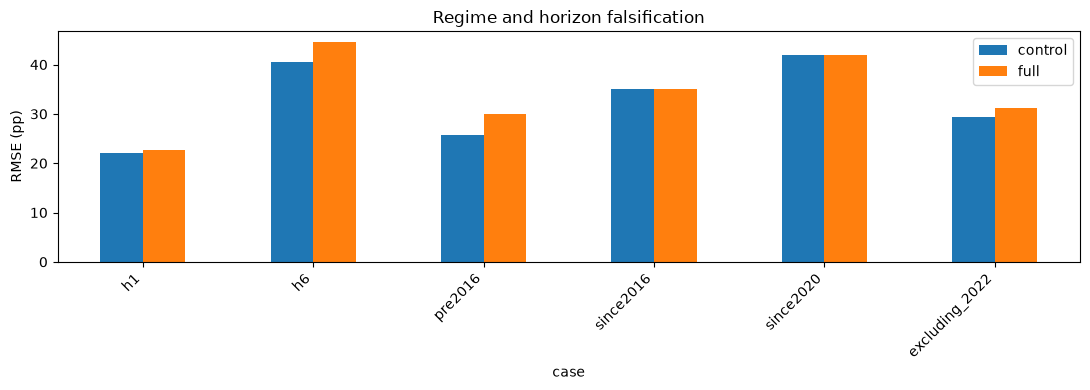

In [12]:
sub=pd.DataFrame(alt).set_index('case')
fig,ax=plt.subplots(figsize=(11,4));sub[['control','full']].plot.bar(ax=ax);ax.set_ylabel('RMSE (pp)');ax.set_title('Regime and horizon falsification');plt.xticks(rotation=45,ha='right');plt.tight_layout();plt.show()


## 3C. Timing placebo limitations
12/24/36-month stale-spread variants deliberately use older data **without circular future wraparound**. They show no stable incremental advantage, but because earlier lags reduce the sample, compare each placebo against its *own* matched controls. These are **not** permutation-test p-values.


In [13]:
lag=[]
for k,v in res['stale_spread_placebos'].items(): lag.append({'lag_case':k,'n':v['n'],'control':v['control']['rmse'],'full':v['full']['rmse'],'delta':v['delta_rmse_control_minus_full']})
display(pd.DataFrame(lag).set_index('lag_case').round(3))


,n,control,full,delta
lag_case,,,,
spread_lag_12,230,31.466,32.071,-0.605
spread_lag_24,218,32.272,33.151,-0.880
spread_lag_36,206,31.287,32.427,-1.140


## 3D. Block bootstrap cannot repair vintage bias
The stored 12-month moving-block bootstrap interval for **control minus full RMSE** is approximately **[−3.540, −0.274] pp**, with implementation-specific Monte Carlo differences possible. The procedure addresses some serial dependence, not revised data, non-tradable spot fills or structural breaks. Do not interpret it as an independently preregistered investment hypothesis test.


Reported block bootstrap CI: [-3.4518315855977932, -0.2481673613890422]


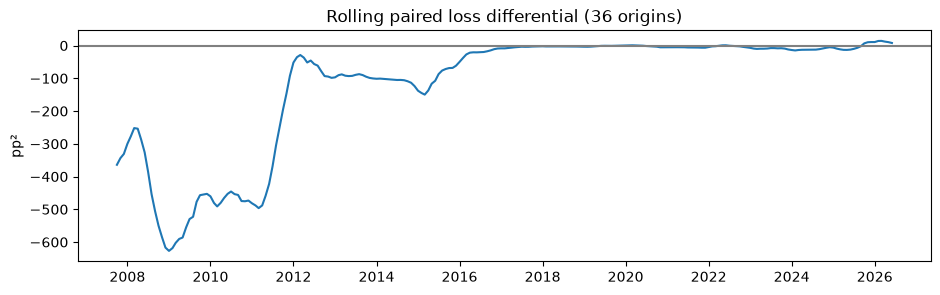

In [14]:
print('Reported block bootstrap CI:',res['bootstrap_95_ci_delta_rmse'])
window=36
rolling_gain=(((pred.y-pred.control)**2-(pred.y-pred.full)**2).rolling(window,min_periods=18).mean())
fig,ax=plt.subplots(figsize=(11,3));ax.plot(pd.to_datetime(pred.date),rolling_gain);ax.axhline(0,color='gray');ax.set_title('Rolling paired loss differential (36 origins)');ax.set_ylabel('pp²');plt.show()


## Bias audit and next steps
Frozen EIA-derived data are **not** historical vintages. Spot-price changes are not tradable futures returns or equity alpha. Next: ALFRED/EIA release calendars, LNG export volumes, storage, weather, JKM/TTF netbacks, futures curve with rolls/fees, and company-level earnings revisions. See README.md and source register.


In [15]:
run(write=True)
print('Wrote results/oos_predictions.csv and results/metrics.json')

Wrote results/oos_predictions.csv and results/metrics.json


## 4A. Bias register and inference grade
| Risk | Observed status | Required upgrade |
|---|---|---|
| Release-time information | t−1 monthly convention | original EIA release calendars |
| Historical revision | **FAIL**: frozen mirror vs true vintages | timestamped primary data |
| Look-ahead labels | u+h ≤ t−1 purge | validate with actual availability |
| Overlapping targets | primary 4-month effective spans | block-aware and nonoverlapping tests |
| Commodity choice | WTI not global LNG netback | JKM/TTF, liquefaction/storage |
| Hypothesis search | spread selected exploratorily | preregistered factor universe |
| Executability | spot averages not fill prices | liquid NYMEX chain with rolls |
| Security alpha | no earnings or total returns | dated issuer exposure & delistings |
| Trading costs | no P&L | fees, slippage, capital costs |


## 4B. Future research roadmap: industry to fundamentals to securities
First add time-stamped **LNG export tonnage/feedgas pipeline flow, capacity utilization, storage surprises, weather anomalies and destination netbacks**. Next construct company-by-exposure mapping from contemporaneous annual filings and asset start dates, testing forward EPS revision and margins. Only after dated features and issuer universe are available should industry-neutral **rank IC**, cost-adjusted top–bottom return spreads and turnover be calculated. Keep an untouched prospective holdout to distinguish discovery from multiple testing.


## 5. Final verdict and reproduction
**Rejected incremental spread factor.** Structural U.S. LNG infrastructure growth may persist, but the tested relative-price spread worsens out-of-sample Henry Hub spot-price forecasts and supplies **no demonstrated futures or equity alpha**. New chart cells are currently unexecuted until notebook run-all/CI verifies them. Reproduce from this directory using `pip install -r requirements.txt`, `python -m unittest discover -s tests -v`, and `jupyter nbconvert --execute --to notebook research.ipynb --output executed.ipynb`. Do not cite an RMSE as portfolio profitability.
